<a href="https://colab.research.google.com/github/rahulraj710/AML-CID/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("/content/AML_CID_practice_sample.csv")

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)

display(df.head())

print(df["Label"].value_counts())

Dataset shape: (28307, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,80,204,2,0,0,0,0,0,0.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,53,336,2,2,82,338,41,41,41.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,53,255,2,2,104,352,52,52,52.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,53,190,2,2,88,188,44,44,44.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,15122,6983953,1,5,6,30,6,6,6.0,0.0,...,32424.0,0.0,32424,32424,6951529.0,0.0,6951529,6951529,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


Label
BENIGN                      22734
DoS Hulk                     2336
PortScan                     1593
DDoS                         1278
DoS GoldenEye                  99
FTP-Patator                    72
DoS Slowhttptest               54
SSH-Patator                    54
DoS slowloris                  49
Bot                            18
Web Attack � Brute Force       13
Web Attack � XSS                7
Name: count, dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/cicids2017_combined.csv"

df = pd.read_csv(file_path, nrows=10000)

df.columns = df.columns.str.strip()

print(df.shape)
display(df.head())

(10000, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [ ]:

import pandas as pd

file_path = "/content/drive/MyDrive/cicids2017_combined.csv"

label_counts = pd.Series(dtype="int64")
total_rows = 0

# Read the dataset in groups of 50,000 rows
for chunks in pd.read_csv(file_path, chunksize=50000):

    # Clean column names
    chunks.columns = chunks.columns.str.strip()

    # Count each traffic category
    counts = chunks["Label"].value_counts()

    # Combine counts
    label_counts = label_counts.add(counts, fill_value=0)

    # Count the total rows
    total_rows += len(chunks)

# Display the results
label_counts = label_counts.astype(int)

print("Total records:", total_rows)
print("\nTraffic categories:")
print(label_counts.sort_values(ascending=False))


Total records: 2830743

Traffic categories:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
dtype: int64


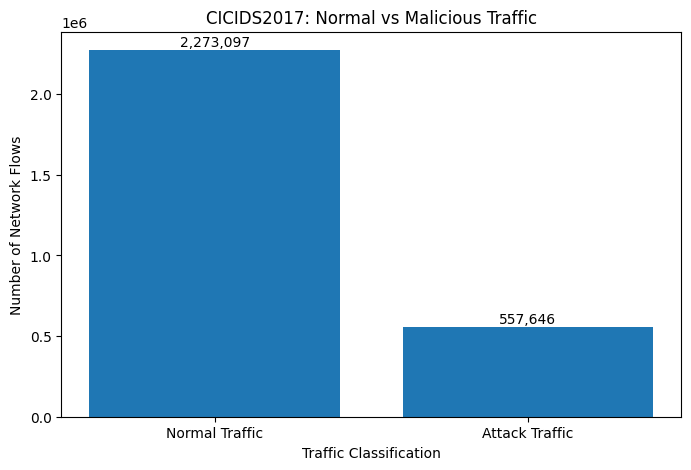

In [ ]:

import matplotlib.pyplot as plt

# Combine the 14 attack categories into one group
normal = label_counts["BENIGN"]
attacks = label_counts.sum() - normal

# Create our two categories
categories = ["Normal Traffic", "Attack Traffic"]
values = [normal, attacks]

# Create the graph
plt.figure(figsize=(8, 5))
plt.bar(categories, values)

# Add a title and labels
plt.title("CICIDS2017: Normal vs Malicious Traffic")
plt.xlabel("Traffic Classification")
plt.ylabel("Number of Network Flows")

# Add record counts above the bars
for i, value in enumerate(values):
    plt.text(i, value + 20000, f"{value:,}", ha="center")

# Save the graph for our report
plt.savefig("traffic_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()
